# Research Lab — Capital Market Assumptions & Portfolio Construction
Inspect every CMA method, the judge's weighting, and stress the portfolio-construction methods.

In [1]:
import json, pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
from meridian.pipelines.target_date import run
from meridian.policy import load_policy, load_universe
from meridian import entities
from meridian.analytics import core as A
from meridian.analytics.optimizers import PC_METHODS, Bounds

In [2]:
res = run(as_of='2026-10-31')
r = json.loads((res.out_dir/'results.json').read_text())
cma = pd.DataFrame(r['cma']).set_index('name')
cma.drop(columns=['asset'])

,historical,equilibrium,building_block,cape_yield,regime_adjusted,auto_blend,judge,judge_minus_blend,vol,yield_based
name,,,,,,,,,,
US Large Cap Equity,0.0803,0.0956,0.0537,0.0584,0.0703,0.0717,0.0673,-0.0044,0.1550,NaN
US Small/Mid Cap Equity,0.0708,0.1084,0.0626,0.0745,0.0608,0.0754,0.0759,0.0004,0.1950,NaN
International Developed Equity,0.0546,0.0967,0.0766,0.0846,0.0446,0.0714,0.0719,0.0004,0.1650,NaN
Emerging Markets Equity,0.0449,0.1143,0.0942,0.0957,0.0349,0.0768,0.0832,0.0064,0.2150,NaN
Global Real Estate (REITs),0.0401,0.1046,0.0758,0.0766,0.0301,0.0654,0.0672,0.0018,0.1950,NaN
Diversified Commodities,0.0128,0.0572,NaN,NaN,0.0385,0.0367,0.0378,0.0011,0.1650,0.0385
US Core Bond (Aggregate),0.0469,0.0408,NaN,NaN,0.0455,0.0442,0.0440,-0.0002,0.0450,0.0435
US Long Treasury,0.0574,0.0353,NaN,NaN,0.0495,0.0474,0.0477,0.0002,0.1200,0.0475
Short-Term TIPS,0.0364,0.0396,NaN,NaN,0.0390,0.0385,0.0388,0.0003,0.0300,0.0390


## Judge vs. auto-blend
Where did the CMA judge depart most from a naive average of methods — and why?

In [3]:
ledger = [json.loads(l) for l in (res.out_dir/'ledger.jsonl').read_text().splitlines()]
judge = pd.DataFrame([{'asset': x['portfolio_scope'][0], 'final': x['output']['expected_return'], 'path': x['output']['judge_path'], 'rationale': x['rationale']} for x in ledger if x['step'].endswith('cma-judge')])
judge.sort_values('final', ascending=False)

,asset,final,path,rationale
3,emerging_eq,0.0832,offline,Valuations cheap (CAPE≈15): tilt to historical...
1,us_small_mid_cap,0.0759,offline,Valuations near normal (CAPE≈22): balanced ble...
2,intl_developed_eq,0.0719,offline,Valuations near normal (CAPE≈18): balanced ble...
0,us_large_cap,0.0673,offline,Valuations stretched (CAPE≈34): tilt to valuat...
4,global_reits,0.0672,offline,Valuations near normal (CAPE≈21): balanced ble...
11,em_debt,0.0580,offline,Fixed income/cash: starting yield net of expec...
9,us_high_yield,0.0544,offline,Fixed income/cash: starting yield net of expec...
7,us_long_treasury,0.0477,offline,Fixed income/cash: starting yield net of expec...
6,us_core_bond,0.0440,offline,Fixed income/cash: starting yield net of expec...
10,intl_bond_hedged,0.0424,offline,Fixed income/cash: starting yield net of expec...


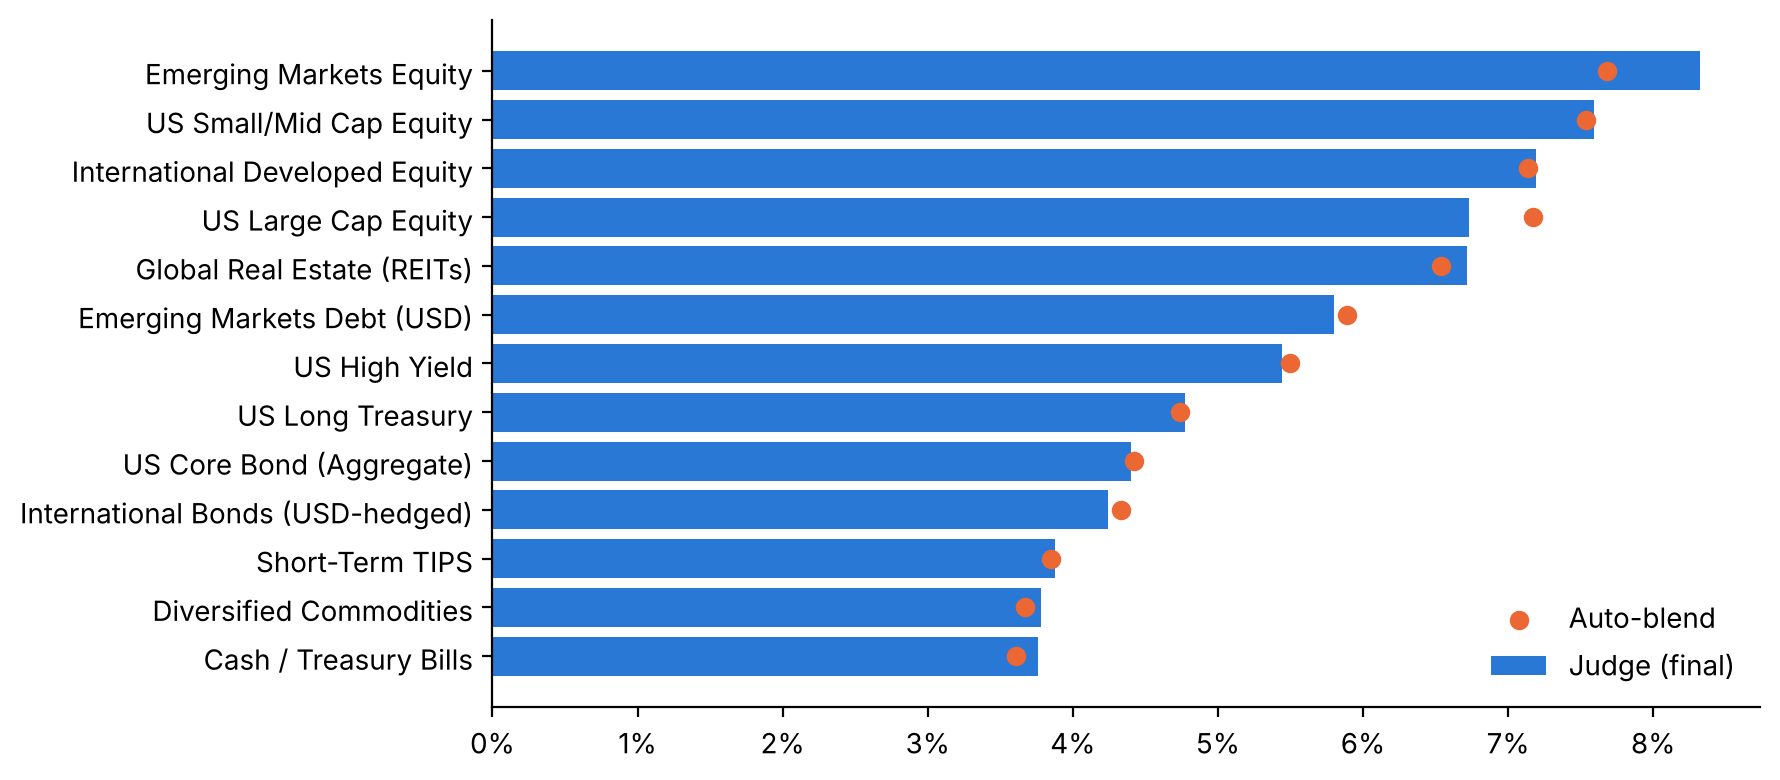

In [4]:
fig, ax = plt.subplots(figsize=(9,4))
c = cma.sort_values('judge')
ax.barh(c.index, c['judge'], color='#2a78d6', label='Judge (final)')
ax.scatter(c['auto_blend'], c.index, color='#eb6834', zorder=3, label='Auto-blend')
ax.xaxis.set_major_formatter(lambda x,_: f'{x:.0%}'); ax.legend(frameon=False); ax.spines[['top','right']].set_visible(False); plt.tight_layout(); plt.show()

## Sensitivity: how does each PC method react if equity CMAs move ±1pp?

In [5]:
snap = res.out_dir/'snapshot'
rets = pd.read_csv(snap/'returns.monthly.csv', parse_dates=['date']).pivot_table(index='date', columns='asset_id', values='ret')
pol = load_policy(); rets = rets[pol.assets]
cov, _ = A.ledoit_wolf_cov(rets)
mu = cma.set_index('asset')['judge'].reindex(pol.assets).values if 'asset' in cma else pd.DataFrame(r['cma']).set_index('asset')['judge'].reindex(pol.assets).values
n = pol.neutral_weights(23.2); eqm = pol.group_mask('equity')
b = Bounds(np.maximum(n-0.03,0), n+0.03, [(eqm, eqm@n-0.05, eqm@n+0.05)], 0.0144)
rows = {}
for k,(fam,fn) in PC_METHODS.items():
    w0,_ = fn(mu, cov, n, b); wd,_ = fn(mu-0.01*eqm, cov, n, b); wu,_ = fn(mu+0.01*eqm, cov, n, b)
    rows[k] = {'family': fam, 'equity_base': eqm@w0, 'equity_cma_-1pp': eqm@wd, 'equity_cma_+1pp': eqm@wu, 'turnover_up': np.abs(wu-w0).sum()/2}
pd.DataFrame(rows).T

,family,equity_base,equity_cma_-1pp,equity_cma_+1pp,turnover_up
glide_path_neutral,heuristic,0.8084,0.8084,0.8084,0.0000
max_sharpe_tilt,return_optimized,0.7584,0.7584,0.7584,0.0002
black_litterman_tilt,return_optimized,0.7584,0.7584,0.7647,0.0187
min_variance_tilt,risk_structured,0.7584,0.7584,0.7584,0.0000
max_diversification_tilt,risk_structured,0.7584,0.7584,0.7584,0.0000
risk_budget_tilt,risk_structured,0.8290,0.8290,0.8290,0.0000


Read it this way: risk-structured methods ignore CMAs, so they never move. Return-optimized methods respond to CMA changes until an IPS band binds — when equity is already at the −5pp floor, a further cut changes nothing, and the policy (not the forecast) is in control. This estimation-risk trade-off is what the peer vote and CIO ensemble balance (paper §4.3).